# TASK 3: DATA CLEANING AND QUALITY ASSESSMENT

## Project Overview
This project focuses on identifying and correcting data quality issues in a deliberately messy customer dataset using Python, Pandas, and NumPy. The goal is to transform raw data into a clean, consistent, and analysis-ready dataset.

## Objectives
- Generate a data quality report.
- Identify and handle missing values.
- Detect and remove duplicate records.
- Standardize inconsistent text and date formats.
- Detect and treat outliers using the IQR method.
- Correct data types and validate data ranges.
- Compare data quality before and after cleaning.
- Export the cleaned dataset to a new CSV file.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


## 1. Import Libraries

Import the libraries required for data manipulation, numerical calculations, visualization, and data quality assessment.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 3.0.3


## 2. Load the Dataset

Load the messy customer CSV and inspect its dimensions and first five records. The original dataset will be preserved for the before-and-after comparison.

In [3]:
file_path = Path("data") / "messy_customer_data_cleaning.csv"

if not file_path.exists():
    file_path = Path(
        r"C:\Users\hi\Documents\OIBSIP\Data-Cleaning-Task\data\messy_customer_data_cleaning.csv"
    )

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Place the CSV in the project's data folder."
    )

df = pd.read_csv(file_path, dtype=str)

df.columns = df.columns.str.strip()

df_before = df.copy(deep=True)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 40
Columns: 10


,CustomerID,Name,Gender,Age,JoinDate,City,AnnualIncome,PurchaseAmount,Rating,Email
0,C001,Asha Rao,Female,24,2024-01-15,Hyderabad,450000,1200.50,4.5,asha.rao@example.com
1,C002,Ravi Kumar,Male,29,15/02/2024,HYDERABAD,520000,850,4,ravi.kumar@example.com
2,C003,Meena Shah,F,31,2024/03/10,Mumbai,610000,2300,5,meena.shah@example.com
3,C004,Arjun Patel,M,27,"March 18, 2024",mumbai,480000,950.75,3.5,arjun.patel@example.com
4,C005,Sara Khan,female,35,2024-04-02,Pune,720000,1800,4.2,sara.khan@example.com


## 3. Initial Data Inspection

Inspect the column names, data types, missing values, duplicate records, and basic structure before performing cleaning.

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nFirst 10 rows:")
display(df.head(10))

Column names:
['CustomerID', 'Name', 'Gender', 'Age', 'JoinDate', 'City', 'AnnualIncome', 'PurchaseAmount', 'Rating', 'Email']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      40 non-null     str  
 1   Name            40 non-null     str  
 2   Gender          40 non-null     str  
 3   Age             39 non-null     str  
 4   JoinDate        40 non-null     str  
 5   City            40 non-null     str  
 6   AnnualIncome    39 non-null     str  
 7   PurchaseAmount  40 non-null     str  
 8   Rating          40 non-null     str  
 9   Email           40 non-null     str  
dtypes: str(10)
memory usage: 6.0 KB

Missing values per column:


,Missing Values
CustomerID,0
Name,0
Gender,0
Age,1
JoinDate,0
City,0
AnnualIncome,1
PurchaseAmount,0
Rating,0
Email,0



Exact duplicate rows:
1

First 10 rows:


,CustomerID,Name,Gender,Age,JoinDate,City,AnnualIncome,PurchaseAmount,Rating,Email
0,C001,Asha Rao,Female,24,2024-01-15,Hyderabad,450000,1200.50,4.5,asha.rao@example.com
1,C002,Ravi Kumar,Male,29,15/02/2024,HYDERABAD,520000,850,4,ravi.kumar@example.com
2,C003,Meena Shah,F,31,2024/03/10,Mumbai,610000,2300,5,meena.shah@example.com
3,C004,Arjun Patel,M,27,"March 18, 2024",mumbai,480000,950.75,3.5,arjun.patel@example.com
4,C005,Sara Khan,female,35,2024-04-02,Pune,720000,1800,4.2,sara.khan@example.com
5,C006,Vikram Das,MALE,41,05-04-2024,PUNE,830000,2600,4.8,vikram.das@example.com
6,C007,Nisha Iyer,Female,22,2024-04-20,Chennai,390000,700,3.8,nisha.iyer@example.com
7,C008,Karan Mehta,Male,33,2024-05-01,Chennai,680000,1550,4.1,karan.mehta@example.com
8,C009,Pooja Nair,F,28,2024-05-14,Bengaluru,560000,2100,4.7,pooja.nair@example.com
9,C010,Dev Singh,M,30,2024-05-22,BANGALORE,590000,1100,3.9,dev.singh@example.com


## 4. Data Quality Report

A data quality report identifies missing values, duplicate rows, unexpected data types, and values outside reasonable ranges. It helps determine which cleaning operations are necessary.

In [5]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[col].dtype) for col in df.columns],
    "Missing Values": [df[col].isna().sum() for col in df.columns],
    "Unique Values": [df[col].nunique(dropna=True) for col in df.columns]
})

display(quality_report)

print("Duplicate rows:", df.duplicated().sum())

# Test whether numeric values can be parsed
for col in ["Age", "AnnualIncome", "PurchaseAmount", "Rating"]:
    converted = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
    print(f"{col}: values that cannot be converted =", converted.isna().sum())

,Column,Data Type,Missing Values,Unique Values
0,CustomerID,str,0,39
1,Name,str,0,39
2,Gender,str,0,7
3,Age,str,1,26
4,JoinDate,str,0,39
5,City,str,0,18
6,AnnualIncome,str,1,32
7,PurchaseAmount,str,0,35
8,Rating,str,0,19
9,Email,str,0,39


Duplicate rows: 1
Age: values that cannot be converted = 2
AnnualIncome: values that cannot be converted = 2
PurchaseAmount: values that cannot be converted = 0
Rating: values that cannot be converted = 1


### Data Quality Analysis

The initial report helps identify missing values, inconsistent formatting, duplicate records, and invalid numeric entries. Numeric conversion tests reveal text values that cannot be interpreted as numbers. These issues will be addressed in the cleaning stages below.

## 5. Prepare Data for Cleaning

Trim extra spaces, standardize empty strings as missing values, convert numeric columns, and flag impossible ages or ratings outside the expected range.

In [6]:
clean_df = df.copy(deep=True)

# Remove leading and trailing spaces
for col in clean_df.columns:
    clean_df[col] = clean_df[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Treat empty strings as missing
clean_df = clean_df.replace(r"^\s*$", np.nan, regex=True)

# Convert numeric columns safely
for col in ["Age", "AnnualIncome", "PurchaseAmount", "Rating"]:
    clean_df[col] = pd.to_numeric(
        clean_df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

# Mark impossible ages as missing
clean_df.loc[
    (clean_df["Age"] <= 0) | (clean_df["Age"] > 100),
    "Age"
] = np.nan

# Mark ratings outside the 1–5 scale as missing
clean_df.loc[
    ~clean_df["Rating"].between(1, 5),
    "Rating"
] = np.nan

print("Missing or invalid values after conversion:")
display(clean_df.isnull().sum().to_frame("Missing Values"))

Missing or invalid values after conversion:


,Missing Values
CustomerID,0
Name,0
Gender,0
Age,4
JoinDate,0
City,0
AnnualIncome,2
PurchaseAmount,0
Rating,1
Email,0


## 6. Missing Data Handling

Cleaning decisions:

- Age: use median imputation because the median is less affected by extreme values.
- AnnualIncome: use median imputation because income can be skewed.
- PurchaseAmount: use median imputation for missing values.
- Rating: use median imputation after invalid ratings are marked missing.
- Gender and City: use mode imputation for missing categories.
- JoinDate: remove rows with missing or invalid dates rather than inventing dates.
- CustomerID, Name, and Email: remove rows if essential identifying fields are missing.

These choices preserve useful data while avoiding unsupported assumptions about missing dates or customer identities.

In [8]:
rows_before_drop = len(clean_df)

clean_df["JoinDate"] = pd.to_datetime(
    clean_df["JoinDate"],
    format="mixed",
    errors="coerce",
    dayfirst=True
)

clean_df = clean_df.dropna(
    subset=["CustomerID", "Name", "Email", "JoinDate"]
).copy()

print("Rows removed due to missing essential fields or invalid dates:",
      rows_before_drop - len(clean_df))

# Impute numeric columns using medians
for col in ["Age", "AnnualIncome", "PurchaseAmount", "Rating"]:
    median_value = clean_df[col].median()
    clean_df[col] = clean_df[col].fillna(median_value)

# Standardize categories before filling missing categories
clean_df["Gender"] = (
    clean_df["Gender"].astype("string").str.strip().str.lower()
)

clean_df["Gender"] = clean_df["Gender"].replace({
    "f": "Female",
    "female": "Female",
    "m": "Male",
    "male": "Male"
})

clean_df["City"] = (
    clean_df["City"].astype("string").str.strip().str.title()
)

clean_df["City"] = clean_df["City"].replace({
    "Bangalore": "Bengaluru"
})

# Mode imputation
for col in ["Gender", "City"]:
    mode_values = clean_df[col].mode(dropna=True)
    if not mode_values.empty:
        clean_df[col] = clean_df[col].fillna(mode_values.iloc[0])

print("Missing values after handling:")
display(clean_df.isnull().sum().to_frame("Missing Values"))

Rows removed due to missing essential fields or invalid dates: 1
Missing values after handling:


,Missing Values
CustomerID,0
Name,0
Gender,0
Age,0
JoinDate,0
City,0
AnnualIncome,0
PurchaseAmount,0
Rating,0
Email,0


## 7. Duplicate Removal

Exact duplicates can cause records to be counted more than once. We count and remove exact duplicate rows and report the number removed.

In [9]:
duplicates_before = int(clean_df.duplicated().sum())

clean_df = clean_df.drop_duplicates().copy()

print("Duplicate rows found:", duplicates_before)
print("Duplicate rows removed:", duplicates_before)
print("Rows after removal:", len(clean_df))
print("Duplicates remaining:", clean_df.duplicated().sum())

Duplicate rows found: 1
Duplicate rows removed: 1
Rows after removal: 38
Duplicates remaining: 0


## 8. Standardization

Standardize gender labels, city names, names, and email addresses. Convert joining dates into a consistent datetime type to support accurate sorting and date-based analysis.

In [10]:
clean_df["Gender"] = (
    clean_df["Gender"].astype("string").str.strip().str.lower()
)

clean_df["Gender"] = clean_df["Gender"].replace({
    "f": "Female",
    "female": "Female",
    "m": "Male",
    "male": "Male"
})

clean_df["City"] = (
    clean_df["City"].astype("string").str.strip().str.title()
)

clean_df["City"] = clean_df["City"].replace({
    "Bangalore": "Bengaluru"
})

clean_df["Email"] = (
    clean_df["Email"].astype("string").str.strip().str.lower()
)

clean_df["Name"] = clean_df["Name"].astype("string").str.strip()
clean_df["CustomerID"] = clean_df["CustomerID"].astype("string").str.strip()

print("Gender categories:")
print(sorted(clean_df["Gender"].dropna().unique()))

print("\nCity categories:")
print(sorted(clean_df["City"].dropna().unique()))

print("\nJoinDate data type:")
print(clean_df["JoinDate"].dtype)

Gender categories:
['Female', 'Male']

City categories:
['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Goa', 'Gurgaon', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Pune']

JoinDate data type:
datetime64[us]


## 9. Outlier Detection Using IQR

The Interquartile Range (IQR) method flags unusually low or high numeric values.

IQR = Q3 − Q1

Lower fence = Q1 − 1.5 × IQR

Upper fence = Q3 + 1.5 × IQR

Outliers will be reviewed before deciding whether to retain, cap, or remove them.

In [11]:
numeric_columns = [
    "Age", "AnnualIncome", "PurchaseAmount", "Rating"
]

outlier_report = []

for col in numeric_columns:
    q1 = clean_df[col].quantile(0.25)
    q3 = clean_df[col].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    mask = (
        (clean_df[col] < lower_fence) |
        (clean_df[col] > upper_fence)
    )

    outlier_report.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Fence": lower_fence,
        "Upper Fence": upper_fence,
        "Outlier Count": int(mask.sum())
    })

display(pd.DataFrame(outlier_report).round(2))

,Column,Q1,Q3,IQR,Lower Fence,Upper Fence,Outlier Count
0,Age,27.25,34.75,7.5,16.00,46.00,0
1,AnnualIncome,505000.00,680000.00,175000.0,242500.00,942500.00,0
2,PurchaseAmount,1162.50,1937.50,775.0,0.00,3100.00,2
3,Rating,4.00,4.50,0.5,3.25,5.25,0


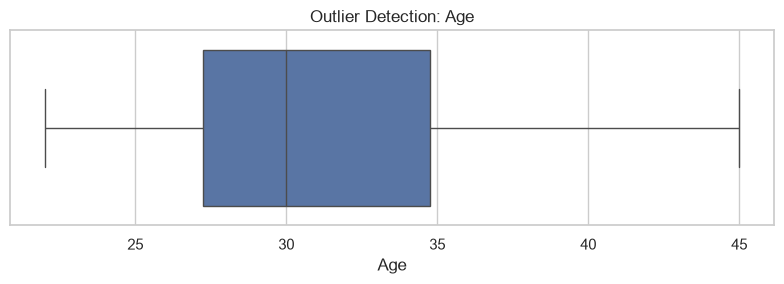

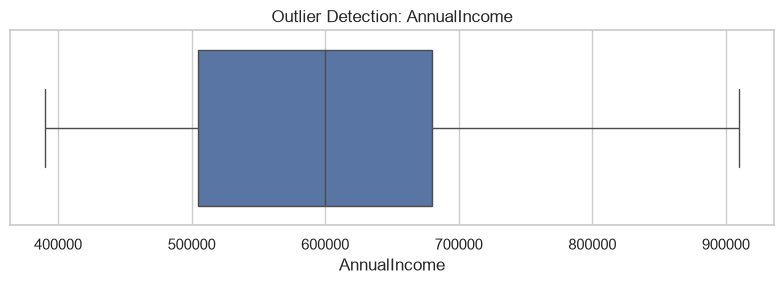

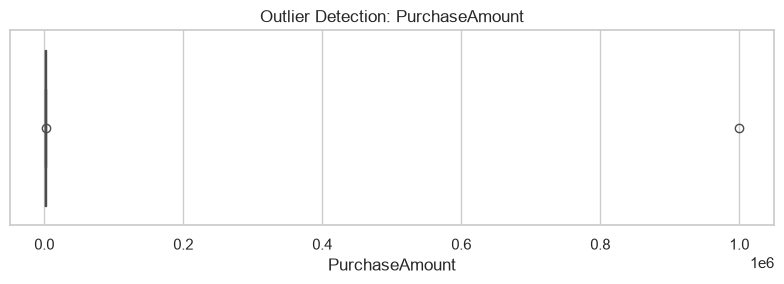

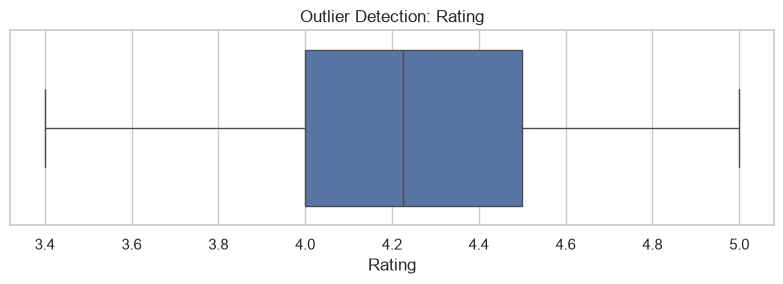

In [12]:
for col in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=clean_df[col])
    plt.title(f"Outlier Detection: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

### Outlier Treatment Decision

Impossible ages and ratings outside the 1–5 range are treated as invalid data before imputation. Plausible but unusually high incomes are retained unless there is evidence that they are incorrect. The extreme purchase amount is capped at the upper IQR fence for this exercise. Capping retains the record while limiting the effect of the extreme value. In real business work, unusual transactions should be verified with the source system before being capped.

In [13]:
q1 = clean_df["PurchaseAmount"].quantile(0.25)
q3 = clean_df["PurchaseAmount"].quantile(0.75)
iqr = q3 - q1

purchase_upper_fence = q3 + 1.5 * iqr

outliers_capped = int(
    (clean_df["PurchaseAmount"] > purchase_upper_fence).sum()
)

clean_df["PurchaseAmount"] = clean_df["PurchaseAmount"].clip(
    upper=purchase_upper_fence
)

print("PurchaseAmount upper IQR fence:", round(purchase_upper_fence, 2))
print("PurchaseAmount values capped:", outliers_capped)
print("Maximum after capping:", round(clean_df["PurchaseAmount"].max(), 2))

PurchaseAmount upper IQR fence: 3100.0
PurchaseAmount values capped: 2
Maximum after capping: 3100.0


## 10. Data Type Correction

Customer identifiers are stored as strings. Joining dates are stored as datetime values, age is stored as an integer, and annual income, purchase amount, and rating are stored as floating-point numbers.

In [14]:
for col in ["CustomerID", "Name", "Gender", "City", "Email"]:
    clean_df[col] = clean_df[col].astype("string")

clean_df["Age"] = clean_df["Age"].round().astype("Int64")
clean_df["JoinDate"] = pd.to_datetime(
    clean_df["JoinDate"], errors="coerce"
)

for col in ["AnnualIncome", "PurchaseAmount", "Rating"]:
    clean_df[col] = clean_df[col].astype("float64")

clean_df.info()
display(clean_df.head())

<class 'pandas.DataFrame'>
Index: 38 entries, 0 to 39
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   CustomerID      38 non-null     string        
 1   Name            38 non-null     string        
 2   Gender          38 non-null     string        
 3   Age             38 non-null     Int64         
 4   JoinDate        38 non-null     datetime64[us]
 5   City            38 non-null     string        
 6   AnnualIncome    38 non-null     float64       
 7   PurchaseAmount  38 non-null     float64       
 8   Rating          38 non-null     float64       
 9   Email           38 non-null     string        
dtypes: Int64(1), datetime64[us](1), float64(3), string(5)
memory usage: 5.0 KB


,CustomerID,Name,Gender,Age,JoinDate,City,AnnualIncome,PurchaseAmount,Rating,Email
0,C001,Asha Rao,Female,24,2024-01-15,Hyderabad,450000.0,1200.50,4.5,asha.rao@example.com
1,C002,Ravi Kumar,Male,29,2024-02-15,Hyderabad,520000.0,850.00,4.0,ravi.kumar@example.com
2,C003,Meena Shah,Female,31,2024-10-03,Mumbai,610000.0,2300.00,5.0,meena.shah@example.com
3,C004,Arjun Patel,Male,27,2024-03-18,Mumbai,480000.0,950.75,3.5,arjun.patel@example.com
4,C005,Sara Khan,Female,35,2024-02-04,Pune,720000.0,1800.00,4.2,sara.khan@example.com


## 11. Before vs. After Cleaning

Compare row counts, missing cells, duplicate rows, and data type accuracy before and after cleaning. Type accuracy is measured against the intended type for each column.

In [15]:
expected_types = {
    "CustomerID": "string",
    "Name": "string",
    "Gender": "string",
    "Age": "integer",
    "JoinDate": "datetime",
    "City": "string",
    "AnnualIncome": "float",
    "PurchaseAmount": "float",
    "Rating": "float",
    "Email": "string"
}

def type_matches(series, expected):
    if expected == "string":
        return (
            pd.api.types.is_string_dtype(series.dtype)
            or pd.api.types.is_object_dtype(series.dtype)
        )
    if expected == "integer":
        return pd.api.types.is_integer_dtype(series.dtype)
    if expected == "datetime":
        return pd.api.types.is_datetime64_any_dtype(series.dtype)
    if expected == "float":
        return pd.api.types.is_float_dtype(series.dtype)
    return False

def quality_summary(data, stage):
    correct = sum(
        type_matches(data[col], expected)
        for col, expected in expected_types.items()
    )

    total = len(expected_types)

    return {
        "Stage": stage,
        "Row Count": len(data),
        "Null Count": int(data.isnull().sum().sum()),
        "Duplicate Count": int(data.duplicated().sum()),
        "Correctly Typed Columns": f"{correct}/{total}",
        "Dtype Accuracy (%)": round(correct / total * 100, 2)
    }

summary = pd.DataFrame([
    quality_summary(df_before, "Before Cleaning"),
    quality_summary(clean_df, "After Cleaning")
])

display(summary)

,Stage,Row Count,Null Count,Duplicate Count,Correctly Typed Columns,Dtype Accuracy (%)
0,Before Cleaning,40,2,1,5/10,50.0
1,After Cleaning,38,0,0,10/10,100.0


## 12. Final Data Validation

Run final checks to ensure the cleaned dataset has no missing values or exact duplicates, that ages and ratings fall within the expected ranges, and that the date column has the correct data type.

In [16]:
print("Final dataset shape:", clean_df.shape)

print("\nMissing values:")
display(clean_df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", clean_df.duplicated().sum())
print("Age range:", clean_df["Age"].min(), "to", clean_df["Age"].max())
print("Rating range:", clean_df["Rating"].min(), "to", clean_df["Rating"].max())
print("JoinDate dtype:", clean_df["JoinDate"].dtype)

assert clean_df.isnull().sum().sum() == 0, "Missing values remain."
assert clean_df.duplicated().sum() == 0, "Duplicate rows remain."
assert clean_df["Age"].between(1, 100).all(), "Age range check failed."
assert clean_df["Rating"].between(1, 5).all(), "Rating range check failed."
assert pd.api.types.is_datetime64_any_dtype(clean_df["JoinDate"]), "JoinDate is not datetime."

print("\nAll final validation checks passed!")

Final dataset shape: (38, 10)

Missing values:


,Missing Values
CustomerID,0
Name,0
Gender,0
Age,0
JoinDate,0
City,0
AnnualIncome,0
PurchaseAmount,0
Rating,0
Email,0



Duplicate rows: 0
Age range: 22 to 45
Rating range: 3.4 to 5.0
JoinDate dtype: datetime64[us]

All final validation checks passed!


## 13. Export Cleaned Dataset

Save the cleaned data as a new CSV file while preserving the original messy dataset. Verify that the exported CSV can be read back successfully.

In [17]:
output_path = Path("data") / "cleaned_customer_data.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

export_df = clean_df.copy()

# Save dates in a consistent ISO format
export_df["JoinDate"] = export_df["JoinDate"].dt.strftime("%Y-%m-%d")

export_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved successfully!")
print("Location:", output_path.resolve())
print("Rows exported:", len(export_df))
print("Columns exported:", len(export_df.columns))

# Verify export
verified_df = pd.read_csv(output_path)
print("Export verification shape:", verified_df.shape)
display(verified_df.head())

Cleaned dataset saved successfully!
Location: C:\Users\hi\Documents\OIBSIP\Data-Cleaning-Task\data\cleaned_customer_data.csv
Rows exported: 38
Columns exported: 10
Export verification shape: (38, 10)


,CustomerID,Name,Gender,Age,JoinDate,City,AnnualIncome,PurchaseAmount,Rating,Email
0,C001,Asha Rao,Female,24,2024-01-15,Hyderabad,450000.0,1200.50,4.5,asha.rao@example.com
1,C002,Ravi Kumar,Male,29,2024-02-15,Hyderabad,520000.0,850.00,4.0,ravi.kumar@example.com
2,C003,Meena Shah,Female,31,2024-10-03,Mumbai,610000.0,2300.00,5.0,meena.shah@example.com
3,C004,Arjun Patel,Male,27,2024-03-18,Mumbai,480000.0,950.75,3.5,arjun.patel@example.com
4,C005,Sara Khan,Female,35,2024-02-04,Pune,720000.0,1800.00,4.2,sara.khan@example.com


## 14. Conclusion

This project demonstrates a structured data cleaning workflow using Python and pandas. The dataset was assessed for missing values, duplicate records, inconsistent formatting, invalid numeric entries, unusual ranges, and incorrect data types.

Missing values were handled using documented column-specific strategies. Exact duplicate records were removed, categories and dates were standardized, and potential outliers were identified using the IQR method. A before-and-after data quality summary was created, and the cleaned dataset was exported to a new CSV file.

The final dataset is more consistent and suitable for further analysis. The original dataset was preserved to support transparency and reproducibility.